# Tarea: el paisaje de pérdida de tu propia red

En esta tarea vas a usar **losslens** para visualizar la función de pérdida alrededor de una red que
**entrenaste en una tarea anterior**, y a explicar lo que ves.

No necesitas saber cómo funciona losslens por dentro. Solo necesitas estas llamadas:

```python
surf = losslens.surface(model, data, loss_fn=nn.CrossEntropyLoss())   # calcular
surf.plot()   surf.plot_3d()   surf.plot_slice()                      # visualizar
surf.summary()                                                        # números
losslens.compare({"A": surf_a, "B": surf_b})                          # comparar
surf.save("a.npz");  surf = losslens.load("a.npz")                    # guardar
```

Documentación completa: https://github.com/iturbideM/losslens

**Qué entregar:** este notebook, ejecutado de principio a fin, con cada *Tu respuesta aquí*
reemplazado por tu respuesta. Las respuestas deben ser breves (unas pocas oraciones) y hacer
referencia a tus gráficas y números.

**Consejos**

- Usa un entorno con GPU (en Colab: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*).
- Prueba primero con una `resolution` baja (por ejemplo 11) para verificar que todo funciona, y luego
  usa el valor por defecto para tus figuras finales.
- Pásale a losslens datos **sin aumento de datos** (*data augmentation*).
- Guarda cada superficie que calcules con `surf.save(...)`, por si el notebook se reinicia.

## Preparación

In [ ]:
%pip install -q git+https://github.com/iturbideM/losslens

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import losslens

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

## Parte 1: Tu modelo y tus datos

Carga (o vuelve a entrenar) la red de tu tarea anterior y los datos con los que fue entrenada.

1. Define la clase de tu modelo y carga sus pesos entrenados.
2. Construye un DataLoader, un Dataset o tensores `(X, y)` con tus datos de **entrenamiento**, sin
   aumento de datos.
3. Escribe la función de pérdida con la que entrenaste.

Si tus batches no son de la forma `(inputs, targets)`, o tu pérdida no es
`loss_fn(model(inputs), targets)`, vas a necesitar `forward=` en lugar de `loss_fn=` (ver la
documentación).

In [5]:
# Definimos un modelo sencillo, con dos capas lineales y una función de activación
# RELU. La red clasifica los dígitos del 0 al 9 a partir de imágenes de 8x8 píxeles del
# dataset Digits de scikit-learn.
class ClasificadorDigitos(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 10),
        )

    def forward(self, x):
        return self.capas(x)


torch.manual_seed(42)
model = ClasificadorDigitos().to(device)

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

# Digits viene incluido en scikit-learn, así que no hace falta descargar archivos aparte.
digits = load_digits()
X = torch.tensor(digits.data / 16.0, dtype=torch.float32) # Dividimos entre 16 para normalizar entre 0 a 1
y = torch.tensor(digits.target, dtype=torch.long)

train_indices, test_indices = train_test_split(
    range(len(y)),
    test_size=0.2,
    random_state=42,
    stratify=digits.target,
)
train_dataset = TensorDataset(X[train_indices], y[train_indices])
test_dataset = TensorDataset(X[test_indices], y[test_indices])
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"Ejemplos de entrenamiento: {len(train_dataset)}; de prueba: {len(test_dataset)}")

Ejemplos de entrenamiento: 1437; de prueba: 360


In [8]:
# CrossEntropyLoss recibe los logits de la red y las etiquetas enteras de cada dígito.
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Entrenamos aquí porque ya están definidos el modelo, los datos y la pérdida.
epochs = 30
for epoch in range(epochs):
    model.train()
    loss_total = 0.0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(inputs), targets)
        loss.backward()
        optimizer.step()
        loss_total += loss.item() * inputs.size(0)

print(f"Pérdida media de entrenamiento: {loss_total / len(train_dataset):.4f}")

model.eval()
correct = 0
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        correct += (model(inputs).argmax(dim=1) == targets).sum().item()
print(f"Exactitud en prueba: {correct / len(test_dataset):.1%}")

Pérdida media de entrenamiento: 0.1961
Exactitud en prueba: 95.6%


## Parte 2: El paisaje de tu modelo

Calcula el paisaje alrededor de tu modelo entrenado con las opciones por defecto, y muestra la
gráfica de contorno, la gráfica 3D y los cortes. Luego imprime el resumen.

In [9]:
# La superficie usa datos de entrenamiento; losslens limita la muestra al tamaño disponible.
surf = losslens.surface(model, train_dataset, loss_fn=loss_fn)
surf.save("surface_base.npz")

Evaluating 625 points on 1437 examples (estimated time: under a second).


losslens: 100%|██████████| 625/625 [00:00<00:00, 2867.46it/s]


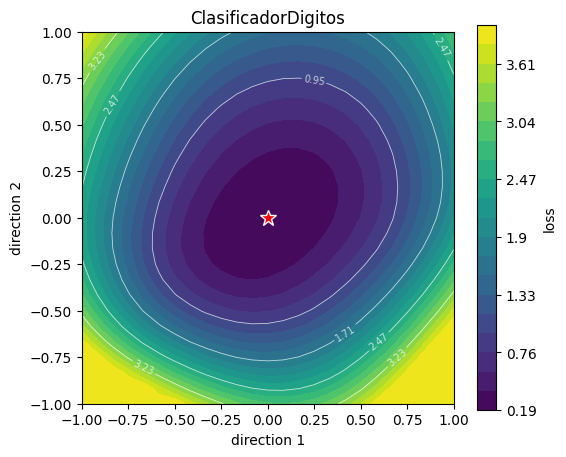

In [10]:
surf.plot()

In [11]:
surf.plot_3d()

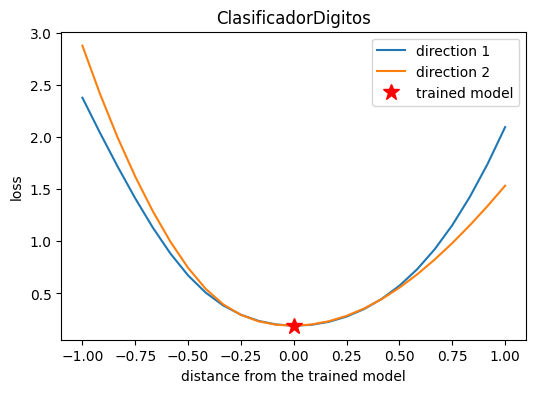

In [12]:
surf.plot_slice()

In [13]:
surf.summary()

ClasificadorDigitos  (scale=1.0, 1437 examples)
  loss of the trained model                     0.1903
  lowest loss on the grid                       0.1903
  where it is (direction 1, direction 2)        (+0.00, +0.00)
  is the trained model the lowest point?        yes
  mean loss increase at 10% of scale            0.01805
  mean loss increase at 25% of scale            0.1017
  mean loss increase at 50% of scale            0.454
  steeper / flatter direction, at 50% of scale  1.062


{'center_loss': 0.19032566693190825,
 'grid_min_loss': 0.19032566693190825,
 'grid_min_at': (0.0, 0.0),
 'min_is_center': True,
 'rise_at_10%': 0.01804584628351122,
 'rise_at_25%': 0.10168010540265085,
 'rise_at_50%': 0.45397751508311335,
 'asymmetry': 1.0621321601207785}

**2.1** Describe la forma del paisaje. ¿Está el modelo entrenado en el fondo de un valle? ¿El
valle es ancho o angosto, redondo o alargado, suave o irregular?

Sí: el contorno muestra un "valle" con una forma cóncava lisa y centrada en el modelo, con curvas cerradas algo ovaladas, no perfectamente redondas. No se ven picos ni irregularidades marcadas en las direcciones exploradas.

**2.2** Usa los números de `summary()` para respaldar tu descripción.

El mínimo de la grilla coincide con el centro: pérdida 0.1903 en (0, 0). La pérdida aumenta en promedio 0.0180 al 10% de la escala y 0.4540 al 50%; la asimetría de 1.062 indica pendientes parecidas, aunque una dirección es algo más pronunciada. Se usaron los 1437 ejemplos de entrenamiento disponibles.

## Parte 3: ¿Es una forma real?

Las dos direcciones son aleatorias. Calcula el paisaje de nuevo con otra `seed`, y compara ambos
con `losslens.compare`.

Evaluating 625 points on 1437 examples (estimated time: under a second).


losslens: 100%|██████████| 625/625 [00:00<00:00, 2514.77it/s]


                                                 Semilla 0   Semilla 123
loss of the trained model                           0.1903        0.1903
lowest loss on the grid                             0.1903        0.1903
where it is (direction 1, direction 2)        (+0.00, +0.00)  (+0.00, +0.00)
is the trained model the lowest point?                 yes           yes
mean loss increase at 10% of scale                 0.01805       0.01747
mean loss increase at 25% of scale                  0.1017        0.1012
mean loss increase at 50% of scale                   0.454        0.4725
steeper / flatter direction, at 50% of scale         1.062         1.569


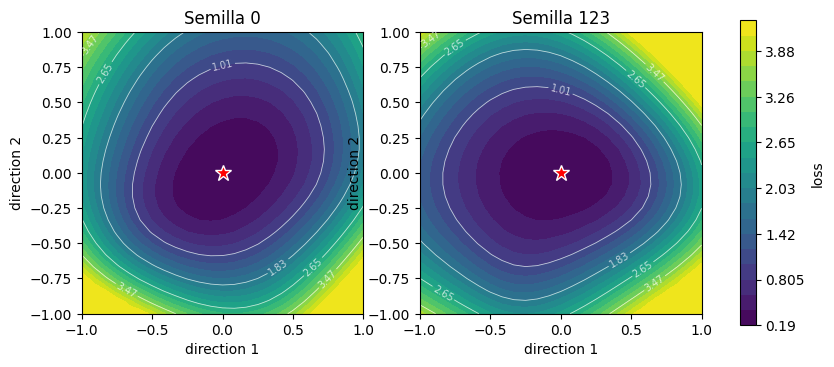

In [14]:
# Cambiar la semilla cambia las direcciones aleatorias con las que se explora el paisaje.
surf_seed123 = losslens.surface(model, train_dataset, loss_fn=loss_fn, seed=123)
surf_seed123.save("surface_seed123.npz")
losslens.compare({"Semilla 0": surf, "Semilla 123": surf_seed123})

**3.1** ¿Se parecen los dos paisajes? ¿Qué te dice eso sobre tu respuesta a la Parte 2?

Los dos paisajes son parecidos: ambos tienen su mínimo en el centro y los aumentos de pérdida al 10% y 25% de la escala son casi iguales. Al 50%, la pérdida sube 0.4540 con la semilla 0 y 0.4725 con la 123; la asimetría cambia de 1.062 a 1.569. La forma general del valle se mantiene, aunque su inclinación depende en parte de las direcciones aleatorias.

## Parte 4: Acercar y alejar

Calcula el paisaje con al menos otros dos valores de `scale`, uno menor y otro mayor que 1.0, y
grafícalos.

Evaluating 625 points on 1437 examples (estimated time: under a second).


losslens: 100%|██████████| 625/625 [00:00<00:00, 3133.29it/s]


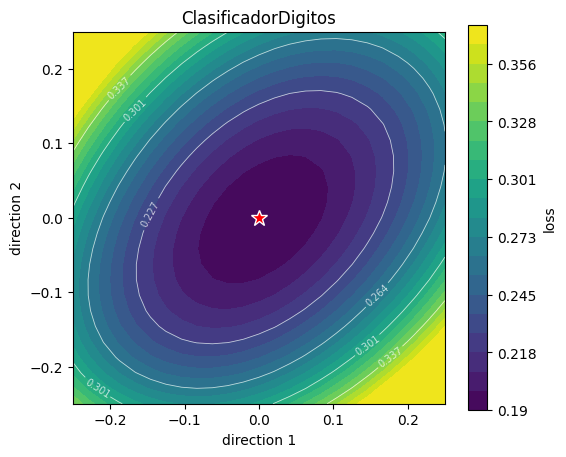

In [15]:
surf_scale_small = losslens.surface(
    model, train_dataset, loss_fn=loss_fn, scale=0.25
)
surf_scale_small.save("surface_scale_025.npz")
surf_scale_small.plot()

Evaluating 625 points on 1437 examples (estimated time: under a second).


losslens: 100%|██████████| 625/625 [00:00<00:00, 3181.50it/s]


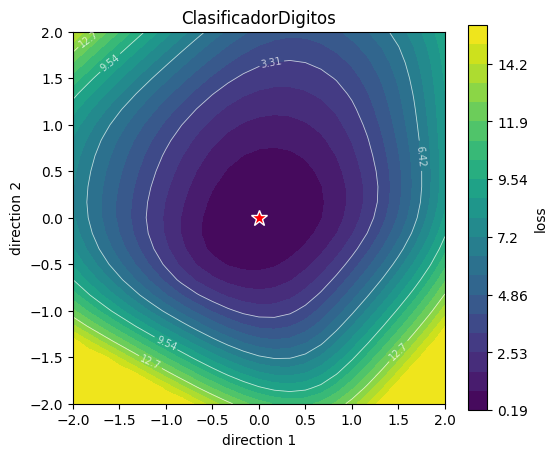

In [16]:
surf_scale_large = losslens.surface(
    model, train_dataset, loss_fn=loss_fn, scale=2.0
)
surf_scale_large.save("surface_scale_2.npz")
surf_scale_large.plot()

**4.1** ¿Qué ves en cada escala? ¿Qué valor de `scale` muestra mejor el paisaje de tu modelo, y
por qué?

Con `scale=0.25` se ve de cerca el valle alrededor del mínimo; con `scale=2.0` se observa una región más amplia. El resumen refleja el cambio: al 50% de la escala, el aumento medio es 0.0238 y 2.143, respectivamente. Para describir el entorno del modelo, `scale=1.0` da un punto medio útil entre el detalle local y la vista amplia.

## Parte 5: Comparar dos modelos

Entrena una **segunda versión** de tu modelo que difiera en una sola cosa, y compara los dos
paisajes con `losslens.compare`. Algunas ideas:

- con y sin *weight decay* (u otra regularización, por ejemplo dropout);
- tamaño de batch chico vs. grande;
- con y sin conexiones residuales (*skip connections*) o BatchNorm;
- una versión angosta vs. una ancha de la red;
- un checkpoint temprano vs. el modelo final.

Usa los mismos `scale` y `n_samples` para ambos.

In [17]:
# Reiniciar la semilla y el generador mantiene iguales la inicialización y el orden de los datos.
torch.manual_seed(42)
model_weight_decay = ClasificadorDigitos().to(device)
train_loader_weight_decay = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
)
optimizer_weight_decay = torch.optim.Adam(
    model_weight_decay.parameters(), lr=1e-3, weight_decay=0.01
)

for epoch in range(epochs):
    model_weight_decay.train()
    loss_total_weight_decay = 0.0
    for inputs, targets in train_loader_weight_decay:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer_weight_decay.zero_grad()
        loss = loss_fn(model_weight_decay(inputs), targets)
        loss.backward()
        optimizer_weight_decay.step()
        loss_total_weight_decay += loss.item() * inputs.size(0)

print(
    "Pérdida media de entrenamiento (weight decay): "
    f"{loss_total_weight_decay / len(train_dataset):.4f}"
)
model_weight_decay.eval()
correct_weight_decay = 0
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        correct_weight_decay += (
            model_weight_decay(inputs).argmax(dim=1) == targets
        ).sum().item()
print(
    "Exactitud en prueba (weight decay): "
    f"{correct_weight_decay / len(test_dataset):.1%}"
)

Pérdida media de entrenamiento (weight decay): 0.2917
Exactitud en prueba (weight decay): 94.4%


Evaluating 625 points on 1437 examples (estimated time: under a second).


losslens: 100%|██████████| 625/625 [00:00<00:00, 2767.35it/s]

                                              Sin weight decay  Con weight decay
loss of the trained model                               0.1903            0.2856
lowest loss on the grid                                 0.1903            0.2856
where it is (direction 1, direction 2)          (+0.00, +0.00)    (+0.00, +0.00)
is the trained model the lowest point?                     yes               yes
mean loss increase at 10% of scale                     0.01805           0.01321
mean loss increase at 25% of scale                      0.1017           0.07244
mean loss increase at 50% of scale                       0.454            0.2985
steeper / flatter direction, at 50% of scale             1.062             1.605


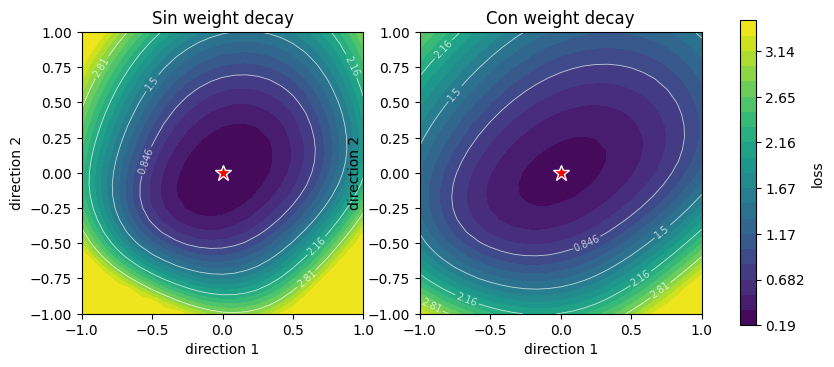

In [18]:
# Mismos escala, resolución, cantidad de ejemplos y semilla que para el modelo base.
surf_weight_decay = losslens.surface(
    model_weight_decay, train_dataset, loss_fn=loss_fn, seed=0
)
surf_weight_decay.save("surface_weight_decay.npz")
losslens.compare(
    {"Sin weight decay": surf, "Con weight decay": surf_weight_decay}
)

**5.1** ¿Qué cambiaste, y qué esperabas ver?

Cambié solo `weight_decay` del optimizador Adam, de 0 a 0.01; mantuve la misma arquitectura, inicialización, datos, orden de batches y épocas. Esperaba que la regularización modificara la forma del valle y quizá mejorara la generalización.

**5.2** ¿Qué ves realmente? Usa las gráficas y la tabla del resumen.

Con weight decay, los aumentos medios de pérdida son menores: el valle resulta más plano en promedio. Sin embargo, la pérdida en el centro es mayor y la asimetría también: una dirección sigue siendo relativamente más empinada.

**5.3** Compara con el desempeño en test de ambos modelos. En tu caso, ¿un paisaje más plano
va de la mano con un mejor desempeño en test?

El modelo sin weight decay obtuvo 95.6% de exactitud en prueba; el que usó weight decay, 94.4%. En esta comparación, el paisaje más plano no vino acompañado de mejor resultado en prueba.

## Parte 6: Conclusiones

**6.1** En unas pocas oraciones: ¿qué aprendiste sobre tu red a partir de su paisaje de pérdida?

En Digits, el modelo queda en el mínimo de la grilla y el paisaje observado es un valle suave; repetirlo con otra semilla conserva la forma general, aunque cambia algo la inclinación. El weight decay aplanó los aumentos de pérdida en promedio, pero no mejoró la exactitud de prueba en esta corrida. Por eso, el paisaje aporta información sobre la pérdida cerca de los pesos entrenados, pero no basta por sí solo para predecir el desempeño en datos nuevos.